In [ ]:
4.4:Frequency Domain 3D Plot

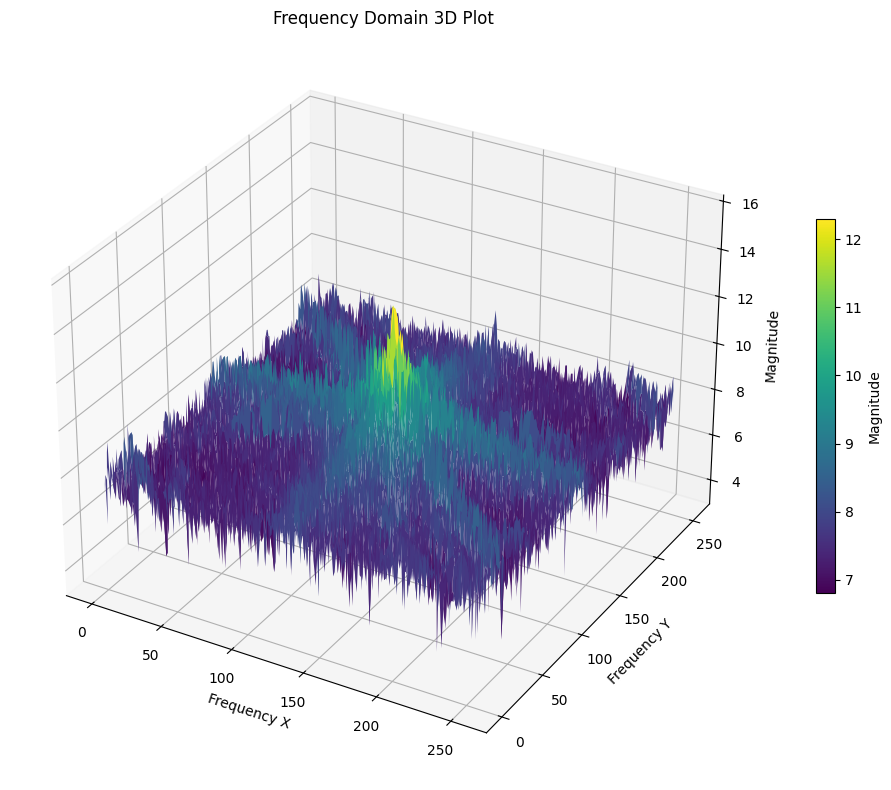

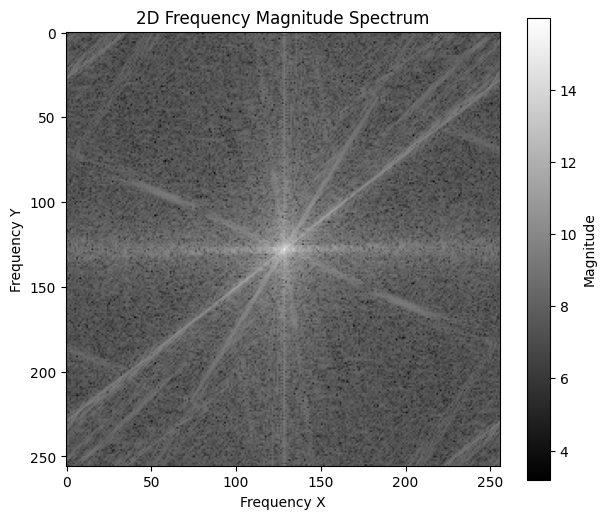

Assignment 4.4 Completed Successfully!
Output saved at: /content/Assignment_4_4_Frequency_3D_Plot.png


In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
import glob
import os

# Step 1: Load Image
image_files = (
    glob.glob('/content/*.png') +
    glob.glob('/content/*.jpg') +
    glob.glob('/content/*.jpeg')
)

if not image_files:
    raise FileNotFoundError("Please upload an image to Colab.")

image_path = next(
    (f for f in image_files if os.path.basename(f) == "image.png"),
    image_files[0]
)

img = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)

if img is None:
    raise ValueError("Image could not be loaded.")

img = cv2.resize(img, (256, 256))

# Step 2: Apply Fourier Transform
F = np.fft.fft2(img)

# Step 3: Shift Zero Frequency to Center
F_shift = np.fft.fftshift(F)

# Step 4: Calculate Magnitude Spectrum
magnitude = np.abs(F_shift)

# Step 5: Apply Log Transformation
magnitude_spectrum = np.log1p(magnitude)

# Step 6: Create X and Y Coordinates
rows, cols = magnitude_spectrum.shape

x = np.arange(cols)
y = np.arange(rows)

X, Y = np.meshgrid(x, y)

# Step 7: Create 3D Surface Plot
fig = plt.figure(figsize=(12, 8))

ax = fig.add_subplot(111, projection='3d')

surface = ax.plot_surface(
    X, Y, magnitude_spectrum,
    cmap='viridis',
    edgecolor='none'
)

# Step 8: Add Labels and Title
ax.set_title("Frequency Domain 3D Plot")

ax.set_xlabel("Frequency X")
ax.set_ylabel("Frequency Y")
ax.set_zlabel("Magnitude")

fig.colorbar(surface, ax=ax, shrink=0.5, label="Magnitude")

plt.tight_layout()
plt.show()

# Step 9: Display 2D Magnitude Spectrum
plt.figure(figsize=(7, 6))

plt.imshow(magnitude_spectrum, cmap='gray')
plt.title("2D Frequency Magnitude Spectrum")
plt.xlabel("Frequency X")
plt.ylabel("Frequency Y")
plt.colorbar(label="Magnitude")

plt.show()

# Step 10: Save Output
output_path = "/content/Assignment_4_4_Frequency_3D_Plot.png"

plt.figure(figsize=(7, 6))
plt.imshow(magnitude_spectrum, cmap='gray')
plt.title("Frequency Domain Magnitude Spectrum")
plt.axis('off')
plt.savefig(output_path, bbox_inches='tight')
plt.close()

print("Assignment 4.4 Completed Successfully!")
print("Output saved at:", output_path)